<a href="https://colab.research.google.com/github/saraxfl/Notebook/blob/main/Collab5_Bloque2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression

plt.rcParams['figure.figsize'] = (10, 4)


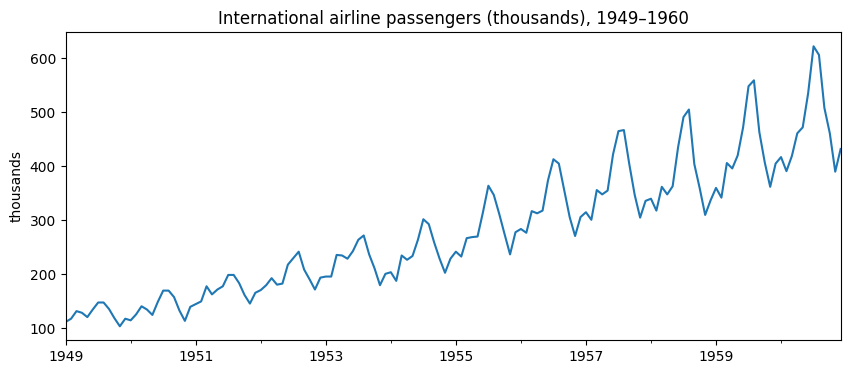

In [9]:

import seaborn as sns

flights = sns.load_dataset('flights')

y = pd.Series(
    flights['passengers'].values,
    index=pd.date_range('1949-01-01', periods=144, freq='MS'),
    name='passengers'
)

assert len(y) == 144 and y.sum() == 40363

y.plot(title='International airline passengers (thousands), 1949–1960')
plt.ylabel('thousands')
plt.show()


In [10]:

train, test = y[:'1958'], y['1959':]

H = len(test)  # forecast horizon: 24 months

print(f'train: {len(train)} months ({train.index[0]:%b %Y} – {train.index[-1]:%b %Y})')
print(f'test : {len(test)} months ({test.index[0]:%b %Y} – {test.index[-1]:%b %Y})')
print(f'max passengers in train: {train.max()}  max in test: {test.max()}')

def rmse(f, a):
    return float(np.sqrt(np.mean((np.asarray(f, float) - np.asarray(a, float)) ** 2)))

def mape(f, a):
    return float(100 * np.mean(np.abs((np.asarray(f, float) - np.asarray(a, float)) / np.asarray(a, float))))

results = {}


train: 120 months (Jan 1949 – Dec 1958)
test : 24 months (Jan 1959 – Dec 1960)
max passengers in train: 505  max in test: 622


In [11]:

snaive = np.tile(train.values[-12:], 2)

results['Seasonal naive'] = (
    rmse(snaive, test),
    mape(snaive, test)
)

print(
    'Seasonal naive  RMSE %.1f  MAPE %.1f%%'
    % results['Seasonal naive']
)


Seasonal naive  RMSE 77.0  MAPE 15.5%


In [12]:

def make_windows(s, p):
    s = np.asarray(s, float)
    X = np.array([s[i - p:i] for i in range(p, len(s))])
    return X, s[p:]


def recursive_forecast(model, history, p, h):
    hist = list(np.asarray(history, float))
    out = []

    for _ in range(h):
        nxt = float(
            model.predict(
                np.array(hist[-p:]).reshape(1, -1)
            )[0]
        )
        out.append(nxt)
        hist.append(nxt)

    return np.array(out)


X_demo, t_demo = make_windows(np.arange(1, 8), 3)
print(X_demo, t_demo)


[[1. 2. 3.]
 [2. 3. 4.]
 [3. 4. 5.]
 [4. 5. 6.]] [4. 5. 6. 7.]


MLP on log levels  RMSE 113.9  MAPE 20.0%
Highest scaled input seen in training: 2.04 | scaled log of Jul 1960: 2.57


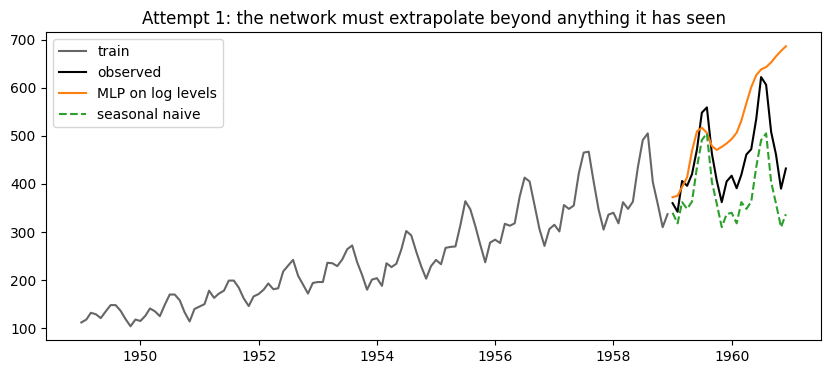

In [13]:

p = 12
l = np.log(y.values)  # log levels, all 144 months

ltr = l[:len(train)]
m, s = ltr.mean(), ltr.std()  # training constants only

Xtr, ttr = make_windows((ltr - m) / s, p)

mlp_levels = MLPRegressor(
    hidden_layer_sizes=(32,),
    activation='relu',
    alpha=1e-3,
    max_iter=5000,
    random_state=0
)

mlp_levels.fit(Xtr, ttr)

f_scaled = recursive_forecast(
    mlp_levels, (ltr - m) / s, p, H
)

f_levels = np.exp(f_scaled * s + m)

results['MLP on log levels'] = (
    rmse(f_levels, test),
    mape(f_levels, test)
)

print(
    'MLP on log levels  RMSE %.1f  MAPE %.1f%%'
    % results['MLP on log levels']
)

print(
    'Highest scaled input seen in training: %.2f | '
    'scaled log of Jul 1960: %.2f'
    % (Xtr.max(), (l[-6] - m) / s)
)

plt.plot(train.index, train, color='0.4', label='train')
plt.plot(test.index, test, 'k', label='observed')
plt.plot(test.index, f_levels, 'C1', label='MLP on log levels')
plt.plot(test.index, snaive, 'C2--', label='seasonal naive')

plt.legend()
plt.title('Attempt 1: the network must extrapolate beyond anything it has seen')
plt.show()


In [18]:

def z_of(Lser):
    Lser = np.asarray(Lser, float)
    return Lser[13:] - Lser[12:-1] - Lser[1:-12] + Lser[:-13]


def undo(z_future, L_hist):
    """Rebuild log levels month by month from forecast z and the observed history."""
    Lh = list(L_hist)
    for zt in z_future:
        Lh.append(zt + Lh[-1] + Lh[-12] - Lh[-13])
    return np.array(Lh[len(L_hist):])


p = 13
ztr = z_of(ltr)

mz, sz = ztr.mean(), ztr.std()
Xz, tz = make_windows((ztr - mz) / sz, p)

print('training windows:', Xz.shape)



def mlp_forecast(seed):
    net = MLPRegressor(
        hidden_layer_sizes=(32,),
        activation='relu',
        alpha=1e-3,
        max_iter=5000,
        random_state=seed
    )
    net.fit(Xz, tz)
    zf = recursive_forecast(net, (ztr - mz) / sz, p, H) * sz + mz
    return np.exp(undo(zf, ltr))


f_mlp = mlp_forecast(0)
results['MLP on transform'] = (rmse(f_mlp, test), mape(f_mlp, test))
print('MLP on RMSE %.1f  MAPE %.1f%%' % results['MLP on transform'])



training windows: (94, 13)
MLP on RMSE 80.1  MAPE 15.1%


Linear AR(13)  RMSE 67.6  MAPE 13.2%


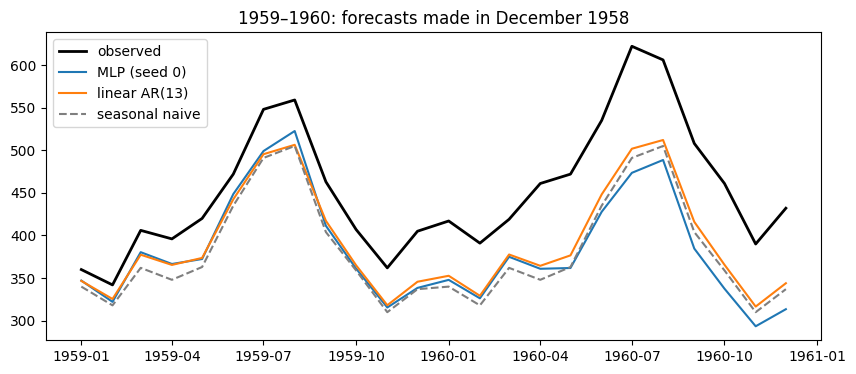

In [19]:

lin = LinearRegression().fit(Xz, tz)

zf_lin = recursive_forecast(
    lin, (ztr - mz) / sz, p, H
) * sz + mz

f_lin = np.exp(undo(zf_lin, ltr))

results['Linear AR(13) on Class 7 transform'] = (
    rmse(f_lin, test),
    mape(f_lin, test)
)

print(
    'Linear AR(13)  RMSE %.1f  MAPE %.1f%%'
    % results['Linear AR(13) on Class 7 transform']
)

plt.plot(test.index, test, 'k', lw=2, label='observed')
plt.plot(test.index, f_mlp, 'C0', label='MLP (seed 0)')
plt.plot(test.index, f_lin, 'C1', label='linear AR(13)')
plt.plot(test.index, snaive, 'C7--', label='seasonal naive')

plt.legend()
plt.title('1959–1960: forecasts made in December 1958')
plt.show()


RMSE over 10 seeds: min 31.4  median 64.1  max 102.3
MAPE over 10 seeds: min 5.7%  median 12.1%  max 19.9%
MLP ensemble  RMSE 67.5  MAPE 13.0%


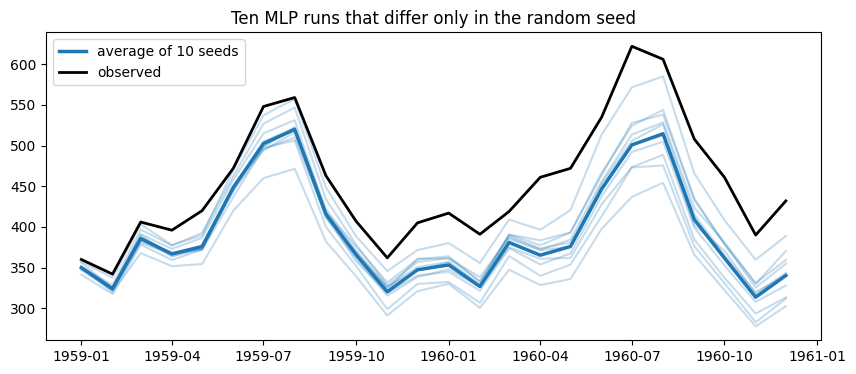

In [20]:

runs = np.array([mlp_forecast(seed) for seed in range(10)])

r_rmse = [rmse(f, test) for f in runs]
r_mape = [mape(f, test) for f in runs]

print('RMSE over 10 seeds: min %.1f  median %.1f  max %.1f'
      % (min(r_rmse), np.median(r_rmse), max(r_rmse)))

print('MAPE over 10 seeds: min %.1f%%  median %.1f%%  max %.1f%%'
      % (min(r_mape), np.median(r_mape), max(r_mape)))

f_ens = np.exp(np.log(runs).mean(0))  # average in log scale

results['MLP, average of 10 seeds'] = (
    rmse(f_ens, test),
    mape(f_ens, test)
)

print('MLP ensemble  RMSE %.1f  MAPE %.1f%%'
      % results['MLP, average of 10 seeds'])

plt.plot(test.index, runs.T, color='C0', alpha=.25)
plt.plot(test.index, f_ens, 'C0', lw=2.5, label='average of 10 seeds')
plt.plot(test.index, test, 'k', lw=2, label='observed')

plt.legend()
plt.title('Ten MLP runs that differ only in the random seed')
plt.show()


In [21]:

table = pd.DataFrame(results, index=['RMSE', 'MAPE']).T
display(table)


,RMSE,MAPE
Seasonal naive,76.994589,15.523355
MLP on log levels,113.949002,20.048996
MLP on Class 7 transform,80.145999,15.073248
MLP on transform,80.145999,15.073248
Linear AR(13) on Class 7 transform,67.591001,13.242705
"MLP, average of 10 seeds",67.528037,12.993782
